# 03 · Transform CityGML polygons into a mesh

**Goal:** turn the parsed surfaces into actual triangle faces while preserving where each face came from.

Our roadmap is Inspect → Parse → **Transform** → Analyze → Visualize. We will preview a filled mesh here; solar suitability and an interactive city viewer come later.

Run with the repository's `.venv` Python environment, from the repository root or `sra_notebooks`. In VS Code choose **Select Kernel → Python Environments → .venv**. No new packages are required.

In [1]:
from pathlib import Path
from collections import Counter
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from IPython.display import display
from gismo_2026_fall_hackathon.citygml import iter_buildings
from gismo_2026_fall_hackathon.meshes import buildings_to_mesh

ROOT = Path.cwd().resolve()
if not (ROOT / "pyproject.toml").exists() and (ROOT.parent / "pyproject.toml").exists():
    ROOT = ROOT.parent
GML_FILE = ROOT / "data/DA_WISE_GML/DA_WISE_GMLs/DA1_3D_Buildings_Merged.gml"
SAMPLE_SIZE = 25
# PROVISIONAL: assume source Z has the same units as projected X/Y.
# This setting is not evidence that the vertical unit has been verified.
Z_SCALE = 1.0
PLANARITY_TOLERANCE = 0.01  # in source XY units, after scaling Z
assert GML_FILE.is_file(), f"Missing local dataset: {GML_FILE}"
assert isinstance(SAMPLE_SIZE, int) and SAMPLE_SIZE > 0
buildings = list(iter_buildings(GML_FILE, limit=SAMPLE_SIZE))
assert buildings, "No buildings found"
print(f"{len(buildings)} buildings from {GML_FILE.name}; provisional Z scale = {Z_SCALE}")

25 buildings from DA1_3D_Buildings_Merged.gml; provisional Z scale = 1.0


## 1. What changes from a polygon to a mesh?

A polygon gives the boundary of a face. A triangle mesh fills that boundary with small three-vertex faces. Roofs can be concave and have holes; walls can be vertical. Flattening every face onto the XY plane would collapse a vertical wall.

The reusable mesher therefore:

1. Applies the **explicit** Z scale, then finds a local plane for each polygon.
2. Checks planarity and validates the projected polygon, including holes.
3. Uses constrained triangulation so edges respect concavities and holes.
4. Maps triangle vertices back to original XYZ positions, preserving winding and surface identity.
5. Shares exactly equal vertices and subtracts a local origin to keep mesh coordinates small.

No geometry is repaired or smoothed. A polygon that cannot be meshed is excluded with an issue, not silently replaced with a convex hull. The default planarity tolerance is a processing threshold, not the dataset's survey accuracy.

### Units remain an explicit assumption

[NYC's metadata](https://github.com/CityOfNewYork/nyc-geo-metadata/blob/main/Metadata/Metadata_3DBuildingModel.md) specifies horizontal State Plane feet and discusses vertical accuracy, but does not explicitly establish the GML's vertical unit or datum. **The 1:1 Z scale below is provisional.** Mesh proportions, areas, and slopes are not certified physical measurements.

`buildings_to_mesh(..., z_scale=...)` requires the scale argument so this assumption cannot be hidden. If confirmed vertical units differ, use the factor converting source Z into the horizontal unit.

In [2]:
result = buildings_to_mesh(buildings, z_scale=Z_SCALE,
                           planarity_tolerance=PLANARITY_TOLERANCE)
mesh = result.mesh
print(f"Mesh: {mesh.n_points:,} unique vertices and {mesh.n_cells:,} triangle faces")
print(f"Inspection/meshing issues: {len(result.issues)}")
if result.issues:
    display(pd.DataFrame([asdict(i) for i in result.issues]).head(20))
assert mesh.n_cells > 0, "No usable triangles; inspect issues before proceeding"
assert mesh.is_all_triangles
assert np.isfinite(mesh.points).all()
print("Origin in scaled source coordinates:", mesh.field_data["origin"])
print("Source CRS:", mesh.field_data["source_crs"][0])

Mesh: 512 unique vertices and 862 triangle faces
Inspection/meshing issues: 0
Origin in scaled source coordinates: [1.00327375e+06 1.40124658e+05 6.84230000e+00]
Source CRS: EPSG:2263


## 2. Every triangle keeps its source identity

`mesh` is a PyVista `PolyData` object. `mesh.points` contains local XYZ vertices, and `mesh.faces` contains triangle connectivity. `mesh.cell_data` holds one value per triangle.

Building and owner IDs distinguish whole buildings from nested parts. Surface kind retains the roof/wall/ground distinction. Polygon and surface indices provide a source lookup even when a source ID is absent (stored as an empty string). Each index is local to its parent; use the ownership fields with it. Building indices refer to the input sample order.

The parsed `buildings` still hold original metadata such as BIN; use `building_index` to retrieve the top-level building's complete record.

In [3]:
face_table = pd.DataFrame({key: np.asarray(values) for key, values in mesh.cell_data.items()})
display(face_table.head(12))
surface_table = (face_table.groupby(
    ["building_index", "building_id", "owner_path", "surface_index", "surface_id", "surface_kind"],
    dropna=False).size().rename("triangles").reset_index())
display(surface_table.head(12))
display(face_table.groupby("surface_kind").size().rename("triangles").to_frame())
print("First triangle's building metadata:", buildings[int(face_table.iloc[0]["building_index"])].metadata)

,building_index,building_id,owner_id,owner_path,surface_index,surface_id,surface_kind,polygon_index,polygon_id
0,0,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,0,gml_G73EI5D84XNG6BTW7RBQKARYXFGFBMWRIZET,RoofSurface,0,
1,0,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,0,gml_G73EI5D84XNG6BTW7RBQKARYXFGFBMWRIZET,RoofSurface,0,
2,0,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,0,gml_G73EI5D84XNG6BTW7RBQKARYXFGFBMWRIZET,RoofSurface,0,
3,0,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,0,gml_G73EI5D84XNG6BTW7RBQKARYXFGFBMWRIZET,RoofSurface,0,
4,0,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,1,gml_AWDTFCCAUHPYIQ209FIFPFQDY87RB58G6AVL,GroundSurface,0,
5,0,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,1,gml_AWDTFCCAUHPYIQ209FIFPFQDY87RB58G6AVL,GroundSurface,0,
6,0,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,1,gml_AWDTFCCAUHPYIQ209FIFPFQDY87RB58G6AVL,GroundSurface,0,
7,0,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,1,gml_AWDTFCCAUHPYIQ209FIFPFQDY87RB58G6AVL,GroundSurface,0,
8,0,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,2,gml_NSLH7QDQZR6UT6SCR8E5FA4GFU9ZII2I5RMQ,WallSurface,0,
9,0,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,2,gml_NSLH7QDQZR6UT6SCR8E5FA4GFU9ZII2I5RMQ,WallSurface,0,


,building_index,building_id,owner_path,surface_index,surface_id,surface_kind,triangles
0,0,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,0,gml_G73EI5D84XNG6BTW7RBQKARYXFGFBMWRIZET,RoofSurface,4
1,0,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,1,gml_AWDTFCCAUHPYIQ209FIFPFQDY87RB58G6AVL,GroundSurface,4
2,0,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,2,gml_NSLH7QDQZR6UT6SCR8E5FA4GFU9ZII2I5RMQ,WallSurface,2
3,0,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,3,gml_4AI8CANHCM8FM5Z760FNXECMROHQZXZCTCHQ,WallSurface,2
4,0,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,4,gml_0F3FXXE2W4MMT4MEM82Z85RY26SOX5VKYIH0,WallSurface,2
5,0,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,5,gml_790AAJ0WB474LV0UKSS5YEM0F0E0JCYLXWGM,WallSurface,2
6,0,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,6,gml_I2ZYF4W88XCCFBAF0LB2X94JF9N8FWGZONMR,WallSurface,2
7,0,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,gml_ZL7GWAR67EC4S4ILQ40LOJB7Y8NM02D0HAWS,7,gml_23Z3SO1RXCUICSULUNZI7PTGRX2MQNY2YSN7,WallSurface,2
8,1,gml_VHKIINWDOF6WB4EAYEUNKTM4WOAJO2TUFXZN,gml_VHKIINWDOF6WB4EAYEUNKTM4WOAJO2TUFXZN,0,gml_DQAU2Q1M1FLWJXDU7AWB4PV3MMZVVMROF07H,RoofSurface,2
9,1,gml_VHKIINWDOF6WB4EAYEUNKTM4WOAJO2TUFXZN,gml_VHKIINWDOF6WB4EAYEUNKTM4WOAJO2TUFXZN,1,gml_DAU42ADRDOA0Z8WFAYSX4HHQ0F0OY6QS05Q6,RoofSurface,3


,triangles
surface_kind,
GroundSurface,170
RoofSurface,180
WallSurface,512


First triangle's building metadata: {'DOITT_ID': '294532', 'BIN': '4465953', 'SOURCE_ID': '1210018481'}


## 3. Inspect a filled building mesh

This preview uses Matplotlib so it runs without a browser rendering backend or extra packages. Color means **source surface type**, not solar suitability. Triangle edges show the tessellation.

Change `PREVIEW_BUILDING_INDEX` to inspect another building in the sample. The local axes use source XY units with the configured, provisional Z scale.

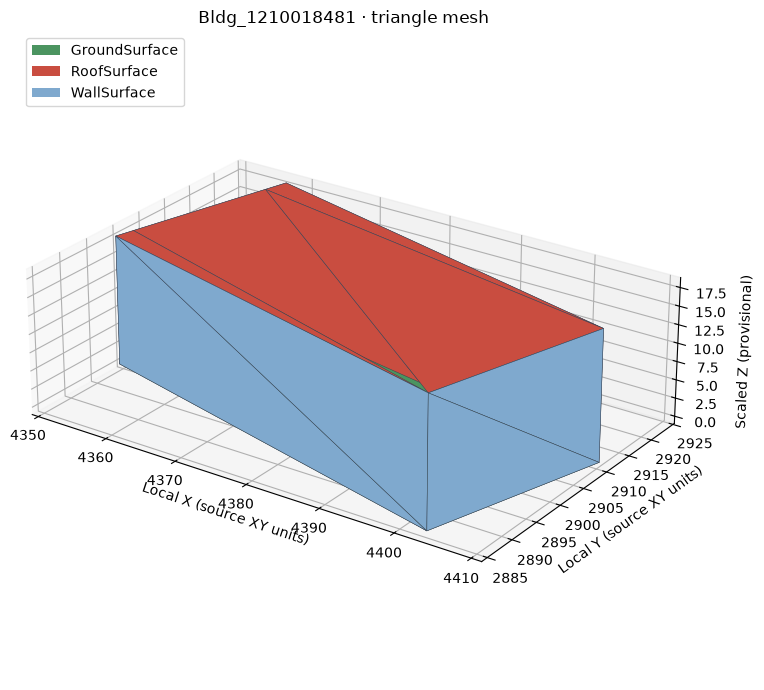

In [4]:
PREVIEW_BUILDING_INDEX = 0
cell_ids = np.flatnonzero(mesh.cell_data["building_index"] == PREVIEW_BUILDING_INDEX)
assert len(cell_ids), "No mesh faces for that building; choose another index or inspect issues"
faces = mesh.faces.reshape(-1, 4)[:, 1:]
triangles = mesh.points[faces[cell_ids]]
kinds = mesh.cell_data["surface_kind"][cell_ids]
colors = {"RoofSurface": "#c94d40", "WallSurface": "#7fa9ce", "GroundSurface": "#4b9460",
          "ClosureSurface": "#a56bb7", "OuterCeilingSurface": "#d99024", "OuterFloorSurface": "#6d7379"}
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
ax.add_collection3d(Poly3DCollection(triangles, facecolors=[colors.get(k, "#888888") for k in kinds],
                                  edgecolors="#374151", linewidths=0.35, alpha=1))
points = triangles.reshape(-1, 3)
lo, hi = points.min(axis=0), points.max(axis=0)
span = np.maximum(hi - lo, 1)
ax.set(xlim=(lo[0] - 1, hi[0] + 1), ylim=(lo[1] - 1, hi[1] + 1), zlim=(lo[2] - 1, hi[2] + 1),
       xlabel="Local X (source XY units)", ylabel="Local Y (source XY units)",
       zlabel="Scaled Z (provisional)", title=f"{buildings[PREVIEW_BUILDING_INDEX].name} · triangle mesh")
ax.set_box_aspect(span)
ax.view_init(elev=25, azim=-55)
ax.legend(handles=[Patch(facecolor=colors.get(k, "#888888"), label=k) for k in sorted(set(kinds))], loc="upper left")
plt.tight_layout()
plt.show()

## 4. Recover source coordinates and reuse the result

Centering does not discard georeferencing. The mesh stores `origin`, `source_crs`, `z_scale`, and a coordinate note in `field_data`.

**Forward transform:** multiply source Z by `z_scale`, then subtract `origin` from XYZ.

**Inverse transform:** add `origin`, then divide Z by `z_scale`. X/Y stay in the source projected CRS; no geographic reprojection has occurred.

In [5]:
recovered_source_xyz = mesh.points.copy() + mesh.field_data["origin"]
recovered_source_xyz[:, 2] /= float(mesh.field_data["z_scale"][0])
display(pd.DataFrame(recovered_source_xyz[:5], columns=["source X", "source Y", "source Z"]))
assert np.isfinite(recovered_source_xyz).all()
print("Recovered source bounds:")
display(pd.DataFrame({"minimum": recovered_source_xyz.min(axis=0),
                      "maximum": recovered_source_xyz.max(axis=0)}, index=["X", "Y", "Z"]))
print("Coordinate note:", mesh.field_data["coordinate_note"][0])

,source X,source Y,source Z
0,1.003274e+06,140139.678432,10.0514
1,1.003274e+06,140139.678432,21.6810
2,1.003279e+06,140141.830987,10.0514
3,1.003279e+06,140141.830987,21.1105
4,1.003279e+06,140141.830987,21.6810


Recovered source bounds:


,minimum,maximum
X,1.003274e+06,1.007684e+06
Y,1.401247e+05,1.430490e+05
Z,6.842300e+00,4.152780e+01


Coordinate note: Local source XY units; Z scaled explicitly; vertical datum unverified


### Optional export

The mesh and tables are ready for later stages in memory. To save them, choose a destination and run:

```python
mesh.save("sample_buildings.vtp")
surface_table.to_csv("sample_surfaces.csv", index=False)
```

VTP retains triangle labels and coordinate-transform metadata; CSV is a non-geometric surface summary. Avoid STL/OBJ when you need these source labels. Reload a VTP with `pyvista.read("sample_buildings.vtp")`. The saved coordinates are **local**, so consumers must use the stored origin and scale to recover source coordinates. No files are exported automatically.

For a desktop interactive inspection outside this automated notebook run, you can use `mesh.plot(scalars="surface_kind", categories=True)`. The guided preview above does not require a GUI or Trame.

### Stage 3 result and limits

We now have labeled triangle meshes, a surface summary, and a reversible coordinate transform. Source winding is preserved but is not yet verified to point outward. Shared exact vertices do not establish that the mesh is watertight or free of self-intersections. Exclusions and parser issues remain visible in `result.issues`.

Stage 4 can calculate surface properties after confirming vertical units and validating orientation. Solar exposure and shadowing remain later work.

References: [Shapely constrained triangulation](https://shapely.readthedocs.io/en/stable/reference/shapely.constrained_delaunay_triangles.html), [PyVista PolyData](https://docs.pyvista.org/api/core/_autosummary/pyvista.polydata).